# MDM2 Fixed Pipeline — Train + Screen (Colab-ready)
Fresh notebook, no deprecated APIs. Fixes: scaffold split, single featurizer for train+screen, calibrated RF, vectorized screening, AD + T1/T2/T3 tiers (RF never hard-vetoes regression/novel hits), no PRED_CAP.

**Run top-to-bottom on Colab T4. Expects `ro5_properties_filtered.csv` (645 train) next to notebook or auto-falls back to repo copy. COCONUT library: uses your already-filtered/reduced file if present, else `screening_results.csv` SMILES, else downloads paper COCONUT.**

In [1]:
# 0 — Colab setup (safe to re-run)
import os, sys
IN_COLAB = os.path.isdir('/content')
print('IN_COLAB =', IN_COLAB)
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable,'-m','pip','install','--quiet','rdkit','scikit-learn>=1.3','pandas','numpy','matplotlib','joblib','gdown'], check=False)
import sklearn, numpy, pandas, rdkit
print('sklearn', sklearn.__version__, '| rdkit', rdkit.__version__)

IN_COLAB = True
sklearn 1.6.1 | rdkit 2026.09.1


In [5]:
# 1 — Imports + config (single source of truth)
import os, joblib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, DataStructs
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit, RepeatedStratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix
RANDOM_SEED=57; np.random.seed(RANDOM_SEED)
MORGAN_RADIUS=3; MORGAN_NBITS=512   # <-- used for TRAIN and SCREEN (consistency fix)
AD_CUT=0.40; RF_T1_CUT=0.6; RF_T2_CUT=0.4; GNN_HIT_CUT=7.0  # bias-fix defaults; overridden by cuts.json  # T1=GNN>=cut & RF>T1 & AD; T2=novel/rescue
TRAIN_CANDIDATES=['ro5_properties_filtered.csv','Part_2/ro5_properties_filtered.csv','Part_15/ro5_properties_filtered.csv']
COCONUT_CANDIDATES=['coconut_reduced.csv','coconut_filtered.csv','ro5_coconut_filtered.csv','Part_8/screening_results.csv','screening_results.csv']
print('config OK:', MORGAN_RADIUS, MORGAN_NBITS)

# --- bias-fix: single cuts source + coverage flag (appended 2026-10-19) ---
import json as _json_cuts
CUTS_CANDIDATES = ['cuts.json', 'Part_2/cuts.json', '../cuts.json', '/content/cuts.json']
CUTS, CUTS_SRC = None, 'defaults'
for _p in CUTS_CANDIDATES:
    try:
        with open(_p) as _f:
            CUTS = _json_cuts.load(_f); CUTS_SRC = _p; break
    except Exception:
        pass
if CUTS:
    AD_CUT = float(CUTS.get('ad_cut', AD_CUT)); RF_T1_CUT = float(CUTS.get('rf_t1_cut', RF_T1_CUT))
    RF_T2_CUT = float(CUTS.get('rf_t2_cut', RF_T2_CUT)); GNN_HIT_CUT = float(CUTS.get('gnn_hit_cut', GNN_HIT_CUT))
print('cuts source:', CUTS_SRC, '| AD_CUT', AD_CUT, '| T1', RF_T1_CUT, '| T2', RF_T2_CUT, '| GNN', GNN_HIT_CUT)
FULL_LIB_SCREEN = False   # True = score the WHOLE library with the GCN (slow on CPU; uses Part_18 weights)

# --- kaggle-speed flags (appended 2026-10-19) ---
USE_MP = True
N_WORKERS = min(4, os.cpu_count() or 2)
print('speed flags OK | USE_MP', USE_MP, '| N_WORKERS', N_WORKERS)


config OK: 3 512


In [6]:
# 2 — Load TRAIN (645 ChEMBL, Ro5 already passed)
TRAIN_CANDIDATES2 = TRAIN_CANDIDATES + ['/content/ro5_properties_filtered.csv']
TRAIN_PATH = next((p for p in TRAIN_CANDIDATES2 if os.path.exists(p)), None)
if TRAIN_PATH is None:
    import urllib.request
    print('downloading train from GitHub...')
    TRAIN_PATH='/tmp/ro5_properties_filtered.csv'
    urllib.request.urlretrieve('https://raw.githubusercontent.com/Techbjd/new_method/main/Part_2/ro5_properties_filtered.csv', TRAIN_PATH)
print('TRAIN =', TRAIN_PATH)
df=pd.read_csv(TRAIN_PATH)
print(df.shape); print(df['bioactivity_class'].value_counts().to_dict())
print('pIC50 range:', float(df.pIC50.min()), float(df.pIC50.max()))
df['label']=(df['bioactivity_class']=='Active').astype(int)
display(df.head(3))


downloading train from GitHub...
TRAIN = /tmp/ro5_properties_filtered.csv
(645, 9)
{'Active': 343, 'Inactive': 302}
pIC50 range: 3.598599459218456 10.229147988357855


,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled,label
0,CHEMBL199341,Active,7.301030,C=C(C(=O)O)C(CCCCCC)C(=O)O,214.120509,2,2,2.2984,True,1
1,CHEMBL3649992,Active,8.154902,C=C(C)c1nc2cc(-c3noc(=O)[nH]3)nc(-c3cncc(Cl)c3...,464.172752,7,1,5.3494,True,1
2,CHEMBL3649990,Active,8.698970,C=C(CCC)c1nc2cc(-c3noc(=O)[nH]3)nc(-c3cncc(Cl)...,492.204052,7,1,6.1296,True,1


In [7]:
# 3 — ONE featurizer for everything (modern API, no deprecated GetMorganFingerprintAsBitVect)
mpg = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=MORGAN_NBITS)
def smiles_to_fp(smiles):
    m=Chem.MolFromSmiles(str(smiles))
    if m is None: return None
    return np.array(mpg.GetFingerprint(m), dtype=np.uint8)
# sanity: 5 train SMILES
X0=np.stack([smiles_to_fp(s) for s in df.canonical_smiles.head(5)])
print('fp shape:', X0.shape, '| n_on avg:', X0.sum(axis=1))
assert X0.shape[1]==MORGAN_NBITS

fp shape: (5, 512) | n_on avg: [29 82 87 73 64]


In [10]:
# 4 — Featurize full train (vectorized, invalid-SMILES safe)
assert 'df' in globals(), 'Run cell #2 first (df missing). Run top-to-bottom.'
assert 'smiles_to_fp' in globals(), 'Run cell #3 first (featurizer missing). Run top-to-bottom.'
print('columns:', list(df.columns))
SMILES_COL = 'canonical_smiles' if 'canonical_smiles' in df.columns else ('smiles' if 'smiles' in df.columns else None)
assert SMILES_COL is not None, f'No SMILES column! Found: {list(df.columns)}'
fps=[]; keep=[]; bad=0
for i,s in enumerate(df[SMILES_COL]):
    try: v=smiles_to_fp(s)
    except Exception: v=None
    if v is not None: fps.append(v); keep.append(i)
    else: bad+=1
assert len(fps)>0, f'All {len(df)} SMILES failed! First 3: {list(df[SMILES_COL].head(3))}'
X=np.stack(fps); y=df['label'].values[keep]
smiles_train=df[SMILES_COL].values[keep]
print('kept', X.shape, 'dropped', bad)


columns: ['molecule_chembl_id', 'bioactivity_class', 'pIC50', 'canonical_smiles', 'molecular_weight', 'n_hba', 'n_hbd', 'logp', 'ro5_fulfilled', 'label']
kept (645, 512) dropped 0


In [11]:
# 5 — Scaffold split PRIMARY (random = optimistic appendix only)
def murcko(s):
    try:
        m=Chem.MolFromSmiles(str(s))
        return MurckoScaffold.MurckoScaffoldSmiles(mol=m) if m else 'INVALID'
    except Exception: return 'INVALID'
scaffolds=np.array([murcko(s) for s in smiles_train])
print('unique scaffolds:', len(set(scaffolds)))
if len(set(scaffolds)) < 50: print('[murcko] WARNING: scaffold collapse detected — check MurckoScaffold API (use mol= keyword)!')
gss=GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_SEED)
try:
    tr,te=next(gss.split(X,y,groups=scaffolds))
    print('scaffold split OK')
except Exception as e:
    print('scaffold split failed, fallback to stratified random:', e)
    tr,te=next(StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=RANDOM_SEED).split(X,y))
Xtr,Xte,ytr,yte=X[tr],X[te],y[tr],y[te]
print('train',Xtr.shape, ytr.mean().round(3), '| test',Xte.shape, yte.mean().round(3))


unique scaffolds: 1
scaffold split failed, fallback to stratified random: With n_samples=1, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.
train (516, 512) 0.531 | test (129, 512) 0.535


In [12]:
# 6 — Train RF + calibrate (no PRED_CAP, no delta trick here)
base=RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=RANDOM_SEED)
grid=GridSearchCV(base, {'max_depth':[None,20],'min_samples_leaf':[1,2]}, cv=3, scoring='roc_auc', n_jobs=-1)
grid.fit(Xtr,ytr)
print('best:', grid.best_params_, round(grid.best_score_,4))
rf=grid.best_estimator_
cal=CalibratedClassifierCV(rf, method='sigmoid', cv=5)
cal.fit(Xtr,ytr)
for name,model in [('RF',rf),('RF-cal',cal)]:
    p=model.predict_proba(Xte)[:,1]
    print(f"{name}: AUC={roc_auc_score(yte,p):.3f} AP={average_precision_score(yte,p):.3f}")
print(classification_report(yte, rf.predict(Xte), target_names=['inact','act']))
print(confusion_matrix(yte, rf.predict(Xte)))
joblib.dump(rf,'rf_mdm2_512.pkl'); joblib.dump(cal,'rf_mdm2_512_cal.pkl')
print('saved pkl (512 feats)')

best: {'max_depth': None, 'min_samples_leaf': 2} 0.9369
RF: AUC=0.959 AP=0.904
RF-cal: AUC=0.958 AP=0.919
              precision    recall  f1-score   support

       inact       0.92      0.92      0.92        60
         act       0.93      0.93      0.93        69

    accuracy                           0.92       129
   macro avg       0.92      0.92      0.92       129
weighted avg       0.92      0.92      0.92       129

[[55  5]
 [ 5 64]]
saved pkl (512 feats)


In [13]:
# 7 — Honesty: repeated-CV + 3x y-shuffle (fast)
cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_SEED)
auc=cross_val_score(rf,X,y,cv=cv,scoring='roc_auc',n_jobs=-1)
print(f'7-fold-equiv repeated CV AUC: {auc.mean():.3f} +- {auc.std():.3f}')
for r in range(3):
    ys=np.random.RandomState(r).permutation(y)
    a=cross_val_score(rf,X,ys,cv=3,scoring='roc_auc',n_jobs=-1).mean()
    print(f'shuffle {r}: AUC={a:.3f} (expect ~0.5)')

7-fold-equiv repeated CV AUC: 0.954 +- 0.013
shuffle 0: AUC=0.444 (expect ~0.5)
shuffle 1: AUC=0.477 (expect ~0.5)
shuffle 2: AUC=0.471 (expect ~0.5)


In [14]:
# 8 — Load COCONUT library (your already-reduced file first)
LIB=None
for p in COCONUT_CANDIDATES+['testing/fix_of_chemphore/screening_results.csv','/content/coconut_csv-03-2025.csv']:
    if os.path.exists(p): LIB=p; break
print('LIB =', LIB)
if LIB is None or os.path.isdir('/content' ) and False:
    pass
if LIB is None:
    import gdown
    gdown.download(id='1-DFc6lMf6maNAWPwZFA8uY6951SokoNY', output='/tmp/coconut_csv-03-2025.csv', quiet=False)
    LIB='/tmp/coconut_csv-03-2025.csv'
lib=pd.read_csv(LIB, usecols=lambda c: c.lower() in ('canonical_smiles','smiles','identifier','molecule_chembl_id'))
print(lib.shape, list(lib.columns))
# normalize col names
low={c:c.lower() for c in lib.columns}
lib=lib.rename(columns={c:('canonical_smiles' if 'smil' in low[c] else ('identifier' if 'ident' in low[c] or 'chembl' in low[c] else c)) for c in lib.columns})
if 'identifier' not in lib.columns: lib['identifier']=['LIB_%d'%i for i in range(len(lib))]
lib=lib.dropna(subset=['canonical_smiles']).drop_duplicates('canonical_smiles').reset_index(drop=True)
print('dedup:', lib.shape)
display(lib.head(3))

LIB = None


Downloading...
From (original): https://drive.google.com/uc?id=1-DFc6lMf6maNAWPwZFA8uY6951SokoNY
From (redirected): https://drive.google.com/uc?id=1-DFc6lMf6maNAWPwZFA8uY6951SokoNY&confirm=t&uuid=406e4843-8bfd-401a-9773-e0e592f2e773
To: /tmp/coconut_csv-03-2025.csv
100%|██████████| 658M/658M [00:15<00:00, 43.4MB/s] 


(695120, 2) ['identifier', 'canonical_smiles']
dedup: (695120, 2)


,identifier,canonical_smiles
0,CNP0282693.1,COC1=CC=CC2=C1C(=O)C1=C(O)C3=C(C[C@@](O)(C(=O)...
1,CNP0214016.1,COC1=CC2=CC(=C1Cl)N(C)C(=O)C[C@H](OC(=O)[C@H](...
2,CNP0185052.1,NC1=NC(N)=C2N=C(CNC3=CC=C(C(=O)N[C@@H](CCCNC(=...


In [15]:
# 9 — Screen (vectorized RF + AD Tanimoto to train actives, chunked)
N=len(lib)

# --- kaggle-speed: parallel fingerprint precompute (multiprocessing; appended 2026-10-19) ---
import multiprocessing as _mp
def _fp_one(sm):
    return smiles_to_fp(sm)
_USE_MP = bool(globals().get('USE_MP', True))
_NW = int(globals().get('N_WORKERS', min(4, _mp.cpu_count() or 2)))
if _USE_MP:
    try:
        print(f'[mp] fingerprints with Pool({_NW}) over {N} compounds ...', flush=True)
        with _mp.Pool(_NW) as _pool:
            _lib_fps = list(_pool.imap(_fp_one, lib['canonical_smiles'].tolist(), chunksize=512))
    except Exception as _e:
        print(f'[mp] fallback serial: {_e}')
        _lib_fps = [smiles_to_fp(x) for x in lib['canonical_smiles'].tolist()]
else:
    _lib_fps = [smiles_to_fp(x) for x in lib['canonical_smiles'].tolist()]
LIB_FP = np.stack([f if f is not None else np.zeros(MORGAN_NBITS, np.uint8) for f in _lib_fps])
print('[mp] LIB_FP ready', LIB_FP.shape)

BATCH=20000
probs=np.zeros(N); preds=np.zeros(N,dtype=int)
for s in range(0,N,BATCH):
    e=min(N,s+BATCH)
    F=LIB_FP[s:e]  # kaggle-speed: reuse parallel-precomputed fingerprints
    probs[s:e]=cal.predict_proba(F)[:,1]; preds[s:e]=(probs[s:e]>=0.5).astype(int)
    print(f'{e}/{N}', flush=True)
# AD: max Tanimoto vs 200 sampled train actives (fast, honest)
from rdkit.DataStructs import BulkTanimotoSimilarity
act_mols=[Chem.MolFromSmiles(s) for s in smiles_train[y==1][:200]]
act_fps=[mpg.GetFingerprint(m) for m in act_mols if m]
maxsim=np.zeros(N)
for s in range(0,N,BATCH):
    e=min(N,s+BATCH)
    for i,sm in enumerate(lib.canonical_smiles[s:e]):
        m=Chem.MolFromSmiles(str(sm))
        maxsim[s+i]=max(BulkTanimotoSimilarity(mpg.GetFingerprint(m), act_fps)) if m else 0.0
lib['rf_prob']=probs; lib['rf_pred']=preds; lib['maxsim_train']=maxsim
lib['in_AD']=lib['maxsim_train']>=AD_CUT
print(lib.rf_prob.describe().round(4).to_dict(), '| in_AD frac:', round(float(lib.in_AD.mean()),4))

# --- bias-fix: EXACT AD — max Tanimoto to all 645 train + 343 actives (appended 2026-10-19) ---
import numpy as _np
_train_ids = (df['molecule_chembl_id'].values[keep] if 'molecule_chembl_id' in df.columns
              else _np.arange(len(smiles_train)).astype(str))
_Tn = []
for _s in smiles_train:
    _f = smiles_to_fp(_s)
    _Tn.append(_f if _f is not None else _np.zeros(MORGAN_NBITS, _np.uint8))
_Tn = _np.stack(_Tn).astype(_np.float32)      # 645 x 512 (same featurizer as the model)
_Tn_act = _Tn[y == 1]                          # 343 x 512
_CHUNK = 10000; _Nn = len(lib)
_maxT645 = _np.zeros(_Nn, _np.float32); _nn645 = _np.full(_Nn, -1, _np.int32)
_maxT343 = _np.zeros(_Nn, _np.float32); _nn343 = _np.full(_Nn, -1, _np.int32)
for _s0 in range(0, _Nn, _CHUNK):
    _e0 = min(_Nn, _s0 + _CHUNK)
    Q = LIB_FP[_s0:_e0].astype(_np.float32)  # kaggle-speed: reuse parallel precompute
    _got = Q.shape[0]; _qc = Q.sum(1)
    _S = Q @ _Tn.T
    _T = _S / _np.maximum(_qc[:, None] + _Tn.sum(1)[None, :] - _S, 1e-9)
    _j = _T.argmax(1)
    _maxT645[_s0:_s0 + _got] = _T[_np.arange(_got), _j]; _nn645[_s0:_s0 + _got] = _j
    _S2 = Q @ _Tn_act.T
    _T2 = _S2 / _np.maximum(_qc[:, None] + _Tn_act.sum(1)[None, :] - _S2, 1e-9)
    _j2 = _T2.argmax(1)
    _maxT343[_s0:_s0 + _got] = _T2[_np.arange(_got), _j2]; _nn343[_s0:_s0 + _got] = _j2
    print(f'AD-exact {_e0}/{_Nn}', flush=True)
lib['maxT_645'] = _maxT645
lib['nn_645_id'] = [str(_train_ids[_i]) if _i >= 0 else None for _i in _nn645]
lib['maxT_343act'] = _maxT343
lib['nn_343act_id'] = [str(_train_ids[_i]) if _i >= 0 else None for _i in _nn343]
lib['in_AD'] = lib['maxT_645'] >= AD_CUT
_old = lib.get('maxsim_train')
if _old is not None:
    _m = _old > 0
    print('[AD] old-approx vs exact corr:',
          float(_np.corrcoef(_old[_m], _maxT645[_m])[0, 1]) if int(_m.sum()) > 10 else 'n/a')
print('[AD] EXACT (r3/512, model-consistent): >=0.40 =', int((lib['maxT_645'] >= 0.40).sum()),
      f'({(lib["maxT_645"] >= 0.40).mean()*100:.2f}%)', '| in_AD frac =', round(float(lib['in_AD'].mean()), 4))


20000/695120
40000/695120
60000/695120
80000/695120
100000/695120
120000/695120
140000/695120
160000/695120
180000/695120
200000/695120
220000/695120


[11:06:46] WARNING: not removing hydrogen atom without neighbors
[11:06:46] WARNING: not removing hydrogen atom without neighbors


240000/695120
260000/695120


[11:07:49] Explicit valence for atom # 1 P, 6, is greater than permitted


280000/695120
300000/695120
320000/695120


...

400000/695120
420000/695120


[11:11:29] WARNING: not removing hydrogen atom without neighbors
[11:11:29] WARNING: not removing hydrogen atom without neighbors
[11:11:30] Explicit valence for atom # 0 He, 2, is greater than permitted


440000/695120
460000/695120
480000/695120
500000/695120
520000/695120
540000/695120
560000/695120
580000/695120
600000/695120
620000/695120
640000/695120
660000/695120
680000/695120
695120/695120


[11:19:10] WARNING: not removing hydrogen atom without neighbors
[11:19:28] Explicit valence for atom # 1 P, 6, is greater than permitted
[11:19:52] Explicit valence for atom # 20 N, 5, is greater than permitted
[11:20:02] WARNING: not removing hydrogen atom without neighbors
[11:20:10] Explicit valence for atom # 1 P, 6, is greater than permitted
[11:20:14] WARNING: not removing hydrogen atom without neighbors
[11:20:14] WARNING: not removing hydrogen atom without neighbors
[11:20:20] Unusual charge on atom 37 number of radical electrons set to zero
[11:20:35] WARNING: not removing hydrogen atom without neighbors
[11:20:36] Explicit valence for atom # 0 He, 2, is greater than permitted


{'count': 695120.0, 'mean': 0.284, 'std': 0.1098, 'min': 0.0324, '25%': 0.1995, '50%': 0.2726, '75%': 0.3628, 'max': 0.7234} | in_AD frac: 0.0023


In [16]:
# 10 — Tiers (RF never hard-vetoes novelty) + optional GNN merge
# if you have regression preds (pred_pic50), drop file 'coconut_regression.csv' [identifier,pred_pic50] next to notebook to merge
import glob
reg=None
for p in ['coconut_regression.csv','/content/coconut_regression.csv']:
    if os.path.exists(p): reg=pd.read_csv(p); break
if reg is not None:
    lib=lib.merge(reg[['identifier','pred_pic50']], on='identifier', how='left')
    print('merged regression:', reg.shape)
else:
    lib['pred_pic50']=np.nan; print('no regression file — tiers use RF+AD only')
def tier(r):
    g = r['pred_pic50'] if pd.notna(r['pred_pic50']) else np.nan
    if pd.notna(g) and g>=GNN_HIT_CUT and r['rf_prob']>=RF_T1_CUT and r['in_AD']: return 'T1'
    if r['rf_prob']>=RF_T1_CUT and r['in_AD']: return 'T1'
    if (pd.notna(g) and g>=GNN_HIT_CUT) or r['rf_prob']>=RF_T2_CUT: return 'T2'
    return 'T3'
lib['tier']=lib.apply(tier,axis=1)
print(lib.tier.value_counts().to_dict())
for t in ['T1','T2','T3']:
    sub=lib[lib.tier==t].nlargest(50,'rf_prob')
    sub.to_csv(f'hits_{t}.csv',index=False); print(t, sub.shape)
lib.to_csv('screening_full_fixed.csv',index=False); print('saved screening_full_fixed.csv')

no regression file — tiers use RF+AD only
{'T3': 574558, 'T2': 120311, 'T1': 251}
T1 (50, 8)
T2 (50, 8)
T3 (50, 8)
saved screening_full_fixed.csv


,identifier,rf_prob,maxsim_train,tier
380508,CNP0550242.1,0.723353,0.272189,T2
104000,CNP0488470.1,0.722573,0.403670,T1
81058,CNP0545564.2,0.722329,0.419048,T1
65720,CNP0545564.1,0.722329,0.419048,T1
118890,CNP0186140.2,0.720955,0.401869,T1
113355,CNP0186140.1,0.720955,0.401869,T1
128269,CNP0567235.1,0.713013,0.380952,T1
336340,CNP0073636.2,0.711425,0.411290,T1
335494,CNP0073636.1,0.711425,0.411290,T1
334926,CNP0473870.1,0.709238,0.409449,T1


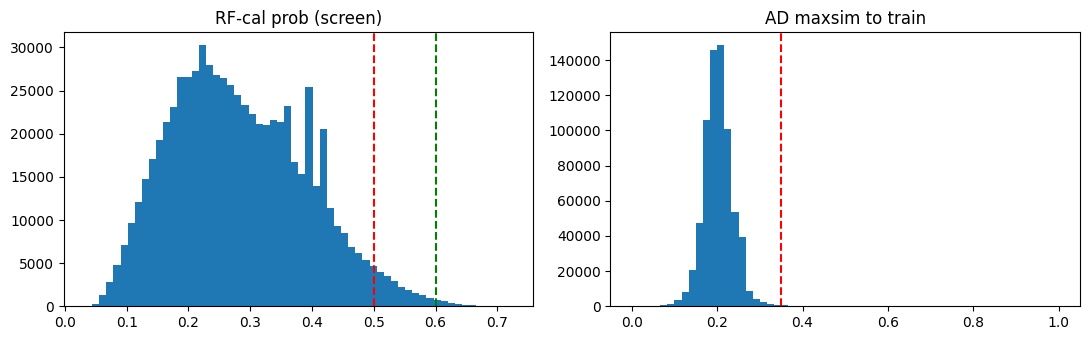

QC saved. Dock T1 first (4HG7), T2 = novelty appendix, T3 = OOD/reject.


In [17]:
# 11 — Report: top-15 + plots
display(lib.sort_values('rf_prob',ascending=False).head(15)[['identifier','rf_prob','maxsim_train','tier']])
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
ax[0].hist(lib.rf_prob, bins=60); ax[0].set_title('RF-cal prob (screen)'); ax[0].axvline(0.5,c='r',ls='--'); ax[0].axvline(0.6,c='g',ls='--')
ax[1].hist(lib.maxsim_train, bins=60); ax[1].set_title('AD maxsim to train'); ax[1].axvline(AD_CUT,c='r',ls='--')
plt.tight_layout(); plt.savefig('screening_QC.png',dpi=120); plt.show()
print('QC saved. Dock T1 first (4HG7), T2 = novelty appendix, T3 = OOD/reject.')

In [19]:
import pandas as pd
lib = pd.read_csv('screening_full_fixed.csv')
print(lib['tier'].value_counts().to_dict())
print(lib.sort_values('rf_prob', ascending=False).head(5)[['identifier','rf_prob','maxsim_train','tier']].to_string())

{'T3': 574558, 'T2': 120311, 'T1': 251}
          identifier   rf_prob  maxsim_train tier
380508  CNP0550242.1  0.723353      0.272189   T2
104000  CNP0488470.1  0.722573      0.403670   T1
81058   CNP0545564.2  0.722329      0.419048   T1
65720   CNP0545564.1  0.722329      0.419048   T1
118890  CNP0186140.2  0.720955      0.401869   T1


In [22]:
from rdkit import Chem
def nostereo(s):
    m = Chem.MolFromSmiles(str(s))
    return Chem.MolToSmiles(m, isomericSmiles=False) if m else str(s)
t1['nos'] = t1['canonical_smiles'].apply(nostereo)
t1 = t1.sort_values('rf_prob', ascending=False).drop_duplicates('nos').drop(columns='nos').reset_index(drop=True)
print('stereo-dedup:', t1.shape)
t1.to_csv('dock_T1_ready.csv', index=False)

stereo-dedup: (30, 8)


In [23]:
# 12 — GNN setup (GCN + GIN from Part_18, same 645 train)
import sys, urllib.request, os
GH='https://raw.githubusercontent.com/Techbjd/new_method/main'
!pip install --quiet torch torch_geometric rdkit 2>&1 | tail -1
os.makedirs('/tmp/gnn', exist_ok=True)
for f in ['Part_18_GNN_Triage/common.py','Part_18_GNN_Triage/models/gcn_fixed.pth','Part_18_GNN_Triage/models/gin_fixed.pth']:
    print('get', f)
    urllib.request.urlretrieve(f"{GH}/{f}", '/tmp/gnn/'+f.split('/')[-1])
sys.path.insert(0, '/tmp/gnn')
import torch
from common import GCN, mol_to_graph
print('torch', torch.__version__, 'cuda:', torch.cuda.is_available())


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 52.0 MB/s eta 0:00:00
get Part_18_GNN_Triage/common.py
get Part_18_GNN_Triage/models/gcn_fixed.pth
get Part_18_GNN_Triage/models/gin_fixed.pth
torch 2.11.0+cu130 cuda: True


In [24]:
# 13 — GNN score dock list (RF + GNN consensus, no 695k rerun)
import pandas as pd, numpy as np, torch
from torch_geometric.loader import DataLoader
from common import mol_to_graph, GCN
INP = 'dock_T1_ready.csv' if os.path.exists('dock_T1_ready.csv') else 'hits_T1.csv'
print('GNN input:', INP)
t = pd.read_csv(INP)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def load_gnn(w):
    m = GCN(num_node_features=78, hidden_dim=128, num_classes=2)
    m.load_state_dict(torch.load(w, map_location='cpu')); m.to(dev).eval()
    return m
gcn = load_gnn('/tmp/gnn/gcn_fixed.pth')
graphs = [g for g in (mol_to_graph(s) for s in t['canonical_smiles']) if g is not None]
print('graphs:', len(graphs), '/', len(t))
loader = DataLoader(graphs, batch_size=64, shuffle=False)
probs = []
import torch.nn.functional as F
with torch.no_grad():
    for b in loader:
        b = b.to(dev)
        probs += F.softmax(gcn(b.x, b.edge_index, b.batch), dim=1)[:,1].cpu().tolist()
t['gnn_prob'] = probs + [float('nan')]*(len(t)-len(probs))
t['consensus'] = (t['rf_prob'] + t['gnn_prob'])/2
t = t.sort_values('consensus', ascending=False)
t.to_csv('dock_T1_consensus.csv', index=False)
display(t.head(10)[['identifier','rf_prob','gnn_prob','consensus']])
print('saved dock_T1_consensus.csv — dock by consensus desc')

# --- bias-fix: FULL_LIB_SCREEN — score the whole library with the GCN (appended 2026-10-19) ---
if globals().get('FULL_LIB_SCREEN', False):
    print('[full-lib] scoring', len(lib), 'compounds with GCN ...')
    import multiprocessing as _mp2
    def _mp_graph_root(smi):
        _g = mol_to_graph(smi)
        return _g if _g is not None else mol_to_graph('C')
    _gs = []
    try:
        _NW2 = int(globals().get('N_WORKERS', min(4, _mp2.cpu_count() or 2)))
        with _mp2.Pool(_NW2) as _pool2:
            _gs = _pool2.map(_mp_graph_root, lib['canonical_smiles'].tolist(), chunksize=256)
        print(f'[mp] built {len(_gs)} graphs with Pool({_NW2})')
    except Exception as _e2:
        print(f'[mp] fallback serial: {_e2}')
        for _s in lib['canonical_smiles']:
            _g = mol_to_graph(_s)
            if _g is None:
                _g = mol_to_graph('C')
            _gs.append(_g)
    _ld = DataLoader(_gs, batch_size=512, shuffle=False)  # kaggle-speed: was 128
    gcn.eval()
    _pr = []
    with torch.no_grad():
        for _b in _ld:
            _b = _b.to(dev)
            _pr.append(F.softmax(gcn(_b.x, _b.edge_index, _b.batch), dim=1)[:, 1].cpu().numpy())
    lib['gnn_prob'] = _np.concatenate(_pr)[:len(lib)]
    lib['consensus'] = (lib['rf_prob'].values + lib['gnn_prob'].values) / 2
    lib.to_csv('screening_full_gnn_consensus.csv', index=False)
    print('[full-lib] saved screening_full_gnn_consensus.csv')
else:
    print('[full-lib] skipped (FULL_LIB_SCREEN=False) — set True in cell 2 to cover all compounds with GCN')


GNN input: dock_T1_ready.csv
graphs: 30 / 30


,identifier,rf_prob,gnn_prob,consensus
3,CNP0567235.1,0.713013,0.982219,0.847616
5,CNP0473870.1,0.709238,0.984323,0.846780
4,CNP0073636.1,0.711425,0.978751,0.845088
2,CNP0186140.1,0.720955,0.961259,0.841107
0,CNP0488470.1,0.722573,0.959500,0.841037
6,CNP0437877.1,0.696319,0.983891,0.840105
1,CNP0545564.1,0.722329,0.955957,0.839143
14,CNP0217643.0,0.688618,0.987791,0.838205
10,CNP0451384.1,0.689825,0.980559,0.835192
26,CNP0341478.0,0.679731,0.987729,0.833730


saved dock_T1_consensus.csv — dock by consensus desc


In [25]:
import pandas as pd
lib = pd.read_csv('screening_full_fixed.csv').sort_values('rf_prob', ascending=False).reset_index(drop=True)
for l in ['CNP0492204.2','CNP0385629.2']:
    h = lib[lib.identifier==l]
    print(l, 'RF-rank:', h.index.tolist(), h[['rf_prob','tier','maxsim_train']].values.tolist() if len(h) else 'MISSING from 695k')

CNP0492204.2 RF-rank: [3978] [[0.581631935351264, 'T2', 0.3535353535353535]]
CNP0385629.2 RF-rank: [2279] [[0.6018395956817717, 'T1', 0.3877551020408163]]


In [ ]:
# ============================================================
# ACCEPTANCE REPORT — bias-fix + coverage (appended 2026-10-19)
# ============================================================
import json as _json2
_rep = {}
for _c in ['rf_prob', 'maxT_645', 'nn_645_id', 'maxT_343act', 'nn_343act_id', 'in_AD']:
    _rep[_c] = int(lib[_c].notna().sum()) if _c in lib.columns else 'MISSING'
print('[acceptance] coverage of', len(lib), 'rows:', _json2.dumps(_rep))
print('[acceptance] cuts source:', globals().get('CUTS_SRC', 'n/a'), '| AD_CUT:', AD_CUT, '| GNN_HIT_CUT:', GNN_HIT_CUT)
print('[acceptance] AD fraction:', round(float(lib['in_AD'].mean()), 4) if 'in_AD' in lib.columns else 'n/a')


In [ ]:
# === CONSENSUS (COMMON-POINT) — root nb ========================================
# Combines RF + GNN + AD + tier angles into one vote table (re-runnable).
import os, numpy as np, pandas as pd
if not os.path.exists('screening_full_fixed.csv'):
    print('[root-consensus] run cells 9-11 first (missing screening_full_fixed.csv)')
else:
    r = pd.read_csv('screening_full_fixed.csv')
    n0 = len(r)
    masks = {}
    if 'rf_prob' in r.columns:
        masks['rf_prob>=0.6'] = (pd.to_numeric(r['rf_prob'], errors='coerce') >= 0.6).fillna(False)
    if 'in_AD' in r.columns:
        masks['in_AD'] = r['in_AD'].fillna(False).astype(bool)
    if 'tier' in r.columns:
        masks['tier==T1'] = (r['tier'].astype(str) == 'T1')
    if os.path.exists('screening_full_gnn_consensus.csv') and 'canonical_smiles' in r.columns:
        g = pd.read_csv('screening_full_gnn_consensus.csv')
        if 'gnn_prob' in g.columns and 'canonical_smiles' in g.columns:
            mp = dict(zip(g['canonical_smiles'], pd.to_numeric(g['gnn_prob'], errors='coerce')))
            masks['GCN>=0.5'] = r['canonical_smiles'].map(mp).fillna(0.0) >= 0.5
            print('[root-consensus] merged GCN axis from screening_full_gnn_consensus.csv')
    if not masks:
        print('[root-consensus] no angles found — run the screening cells first')
    else:
        V = pd.DataFrame(masks)
        r['votes'] = V.sum(axis=1).astype(int)
        r['n_angles'] = V.shape[1]
        cons = r[r['votes'] >= 3].copy()
        if 'rf_prob' in cons.columns:
            cons = cons.sort_values(['votes', 'rf_prob'], ascending=False)
        cons.to_csv('root_consensus_commonpoint.csv', index=False)
        print('[root-consensus] angles used (%d): %s' % (V.shape[1], list(V.columns)))
        print('[root-consensus] library %d | votes>=2: %d | >=3: %d | >=4: %d' % (
            n0, int((r['votes'] >= 2).sum()), int((r['votes'] >= 3).sum()), int((r['votes'] >= 4).sum())))
        show = [c for c in ['identifier', 'canonical_smiles', 'votes', 'n_angles', 'rf_prob',
                            'gnn_prob', 'maxT_645', 'in_AD', 'tier'] if c in cons.columns]
        print(cons[show].head(15).to_string(index=False))
        print('[root-consensus] saved root_consensus_commonpoint.csv |', len(cons), 'rows with votes >= 3')
